# 00 · Covariates from the full Twin data (optional)

*Prepared by Junyoung Park ([jpark01@stanford.edu](mailto:jpark01@stanford.edu)). Analysis code adapted from [tjense25/ADRC-Flagship-lrGS-Code](https://github.com/tjense25/ADRC-Flagship-lrGS-Code) by Tanner D. Jensen (MIT License).*

The QTL, fine-mapping and colocalization steps in notebooks 01 and 02 adjust for
**ancestry PCs** and **molecular-phenotype PCs** ("hidden factors"). These PCs have to be
computed from the *whole* genome and the *whole* molecular layer, so they cannot be
computed from the small locus files in `data/`.

This notebook shows how they were made. It downloads the full SPHERE Twin genotypes and
phenotypes from Hugging Face (about 550 MB), recomputes the PCs, and checks that the result matches
the precomputed covariate files shipped in `data/covariates/`.

**You do not need to run this notebook to follow notebooks 01 and 02.** The download and the PCA take
several minutes. Notebooks 01 and 02 read the precomputed files.

In [1]:
# On Google Colab (Runtime > Change runtime type > R) this first downloads the workshop files.
if (!file.exists("../R/setup.R") && !file.exists("R/setup.R")) {
    if (!dir.exists("sv-finemapping-coloc-tutorial"))
        system("git clone --depth 1 https://github.com/Junkkkk/sv-finemapping-coloc-tutorial.git")
    if (!dir.exists("sv-finemapping-coloc-tutorial/notebooks"))
        stop("Could not download the workshop files from GitHub. Check the internet connection.")
    setwd("sv-finemapping-coloc-tutorial/notebooks")
}
source(if (file.exists("../R/setup.R")) "../R/setup.R" else "R/setup.R")

# Pinned version of the Twin data on Hugging Face.
TWIN_COMMIT <- "02821371c26603cc9460396582eb4ebfbc3257df"
HF_BASE <- paste0("https://huggingface.co/datasets/jpark01/sv-qtl-coloc-data/resolve/",
                  TWIN_COMMIT, "/sv-qtl-coloc/input")
FULL_DIR <- Sys.getenv("TWIN_FULL_DIR", file.path(REPO_DIR, "full_twin"))
OUT_DIR <- file.path(RESULTS_DIR, "covariates_recomputed")
dir.create(OUT_DIR, recursive = TRUE, showWarnings = FALSE)

LAYERS <- c("Plasma", "CSF", "RNA", "Methylation")
files <- c(sprintf("genotype/SV/SV.chr%d.tsv.gz", 1:22),
           file.path(LAYERS, "phenotype.bed"), file.path(LAYERS, "sample_info.tsv"))

options(timeout = 3600)
for (f in files) {
    dest <- file.path(FULL_DIR, f)
    if (!file.exists(dest)) {
        dir.create(dirname(dest), recursive = TRUE, showWarnings = FALSE)
        cat("Downloading", f, "\n")
        tmp <- paste0(dest, ".part")
        ok <- tryCatch(download.file(file.path(HF_BASE, f), tmp, mode = "wb", quiet = TRUE) == 0,
                       error = function(e) FALSE, warning = function(w) FALSE)
        if (!ok) { unlink(tmp); stop("Download failed: ", f, ". Rerun this cell to resume.") }
        file.rename(tmp, dest)
    }
}
cat("Downloaded or found", sum(file.exists(file.path(FULL_DIR, files))), "of", length(files), "files\n")

Downloaded or found 30 of 30 files


## 1. Ancestry PCs from common SV genotypes

Drop SVs with > 50% missing genotypes, keep
SVs with allele frequency between 0.02 and 0.98, run PCA across people, keep the top PCs.

SVs: 73258  common (AF 0.02-0.98): 72918  people: 544 


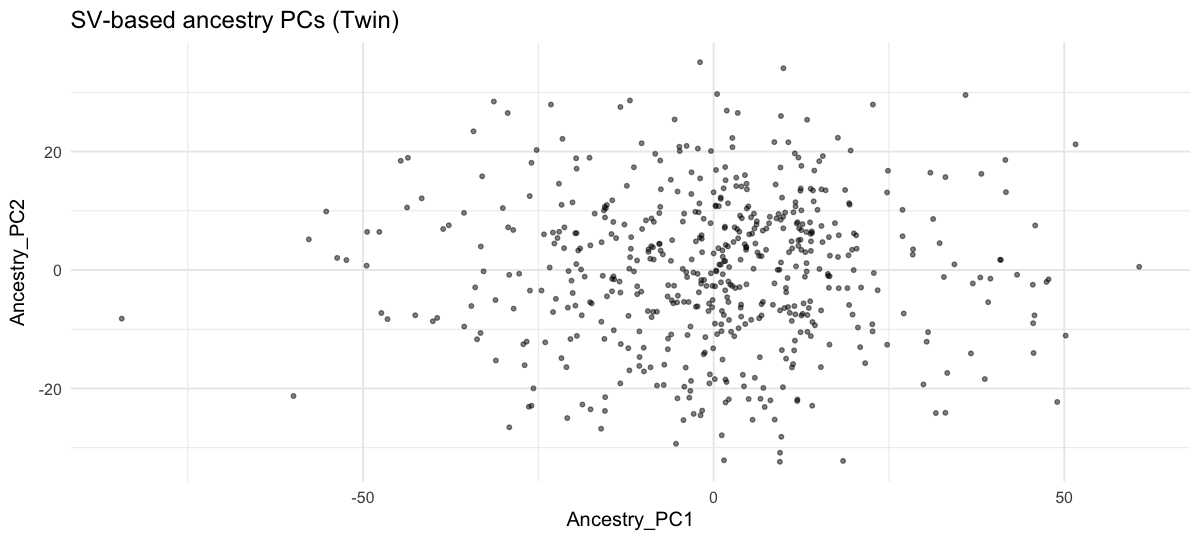

In [2]:
svs <- rbindlist(lapply(1:22, function(i) fread(file.path(FULL_DIR, sprintf("genotype/SV/SV.chr%d.tsv.gz", i)))))
svs.meta <- svs[, 1:5]
svs.mat <- as.matrix(svs[, 6:ncol(svs)])
rm(svs); invisible(gc())

svs.meta$NA_count <- rowSums(is.na(svs.mat))
svs.meta$missingness <- svs.meta$NA_count / ncol(svs.mat)
svs.meta$AC <- rowSums(svs.mat, na.rm = TRUE)
svs.meta$AN <- 2 * (ncol(svs.mat) - svs.meta$NA_count)
svs.meta$AF <- svs.meta$AC / svs.meta$AN

keep <- !(svs.meta$missingness > .5)
svs.mat <- svs.mat[keep, ]
svs.meta <- svs.meta[keep, ]
common <- svs.meta$AF > 0.02 & svs.meta$AF < 0.98
svs.mat.common <- svs.mat[common, ]
cat("SVs:", nrow(svs.mat), " common (AF 0.02-0.98):", nrow(svs.mat.common), " people:", ncol(svs.mat.common), "\n")

ancestry_pcs <- prcomp(t(svs.mat.common), center = TRUE, scale. = FALSE, rank. = 10)$x
colnames(ancestry_pcs) <- paste0("Ancestry_PC", 1:10)
rm(svs.mat, svs.mat.common); invisible(gc())

ggplot(data.frame(ancestry_pcs), aes(Ancestry_PC1, Ancestry_PC2)) +
    geom_point(alpha = .5, size = 1) + labs(title = "SV-based ancestry PCs (Twin)")

Because the Twin contains no real person's record, the ancestry clusters seen in the paper
(Extended Data Figure 1b) are blurred here; the PCs are still used as covariates in the same way.

## 2. Molecular-phenotype PCs and covariate tables

| Layer | People | Phenotype PCs | Ancestry PCs |
|---|---|---|---|
| Plasma proteins | 490 | 120 | 10 |
| CSF proteins | 225 | 100 | 5 |
| PBMC expression | 268 | 120 | 10 |
| Methylation | 544 | 80 | 10 |

Each covariate table has the columns `Sex, Age, AD_Dx, PD_Dx`, then the ancestry PCs, then the
phenotype PCs.

In [3]:
N_PHENO_PCS <- c(Plasma = 120, CSF = 100, RNA = 120, Methylation = 80)
N_ANCESTRY_PCS <- c(Plasma = 10, CSF = 5, RNA = 10, Methylation = 10)

for (layer in LAYERS) {
    bed <- fread(file.path(FULL_DIR, layer, "phenotype.bed"))
    info <- fread(file.path(FULL_DIR, layer, "sample_info.tsv"))
    mat <- as.matrix(bed[, 5:ncol(bed)])
    stopifnot(identical(colnames(mat), info$ID))
    pheno_pcs <- prcomp(t(mat), center = TRUE, scale. = FALSE, rank. = N_PHENO_PCS[[layer]])$x
    colnames(pheno_pcs) <- paste0("PC", seq_len(ncol(pheno_pcs)))
    covariates <- data.table(info[, .(ID, Sex, Age, AD_Dx, PD_Dx)],
                             ancestry_pcs[info$ID, 1:N_ANCESTRY_PCS[[layer]], drop = FALSE],
                             pheno_pcs)
    fwrite(covariates, file.path(OUT_DIR, paste0(layer, ".covariates.tsv.gz")), sep = "\t")
    cat(sprintf("%-12s %4d people  %5d features  %3d covariate columns\n",
                layer, nrow(covariates), nrow(mat), ncol(covariates) - 1))
}

Plasma        490 people   6834 features  134 covariate columns
CSF           225 people   5018 features  109 covariate columns
RNA           268 people  13489 features  134 covariate columns
Methylation   544 people  36271 features   94 covariate columns


## 3. Compare with the precomputed files in `data/covariates/`

PCs are defined only up to their sign, so each column is compared after matching signs.

In [4]:
compare_covariates <- function(layer) {
    a <- fread(file.path(OUT_DIR, paste0(layer, ".covariates.tsv.gz")))
    b <- fread(file.path(DATA_DIR, "covariates", paste0(layer, ".covariates.tsv.gz")))
    stopifnot(identical(names(a), names(b)), identical(a$ID, b$ID))
    diffs <- sapply(names(a)[-1], function(col) {
        x <- a[[col]]; y <- b[[col]]
        min(max(abs(x - y)), max(abs(x + y)))
    })
    data.table(layer = layer, columns = length(diffs), max_abs_difference = max(diffs))
}
rbindlist(lapply(LAYERS, compare_covariates))

layer,columns,max_abs_difference
<chr>,<int>,<dbl>
Plasma,134,0
CSF,109,0
RNA,134,0
Methylation,94,0
